In [3]:
%pylab inline
import os
import numpy as np
import pandas as pd
import astropy.io.fits as pyfits
from astropy.table import Table
import catutil as utilities

import matplotlib as mpl
mpl.rcParams['savefig.dpi'] = 'figure'
mpl.rcParams['savefig.jpeg_quality'] = 100
import matplotlib.pyplot as plt

import matplotlib.lines as mlines

Populating the interactive namespace from numpy and matplotlib


In [4]:
anaDir     =   './wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/'
nbin2      =   60
resolution_bin=np.linspace(0.1,1.,nbin2)
resolution_bin_0  =   resolution_bin[:-1]
resolution_bin_1  =   resolution_bin[1:]
resGrid    =   (resolution_bin_0+resolution_bin_1)/2.
snr_bin    =   np.linspace(0.,80.,nbin2)
snr_bin_0  =   snr_bin[:-1]
snr_bin_1  =   snr_bin[1:]
snrGrid    =   (snr_bin_0+snr_bin_1)/2.
mag_bin    =   np.linspace(22.,25.2,nbin2)
mag_bin_0  =   mag_bin[:-1]
mag_bin_1  =   mag_bin[1:]
magGrid    =   (mag_bin_0+mag_bin_1)/2.
absE_bin   =   np.linspace(0.,2.,nbin2)
absE_bin_0 =   absE_bin[:-1]
absE_bin_1 =   absE_bin[1:]
absEGrid   =   (absE_bin_0+absE_bin_1)/2.

datanames  =   ['gridRes','histRes','gridSnr','histSnr','gridMag','histMag','gridAbsE','histAbsE','num']

/work/xiangchong.li/superonionGW/code/FPFS_Private/FPFSBASE/python/catutil.py:1722: RuntimeWarning: invalid value encountered in less
  (get_imag_A10(catalog)<25.5)& \


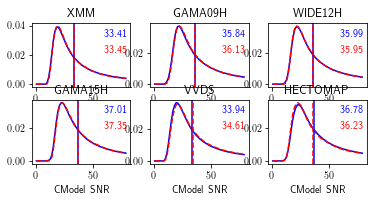

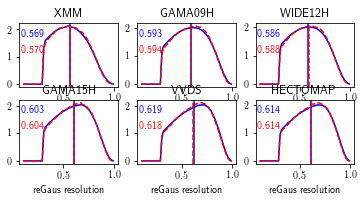

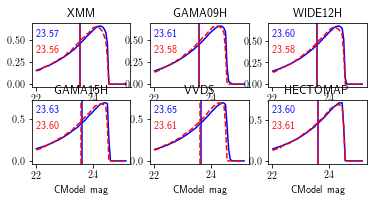

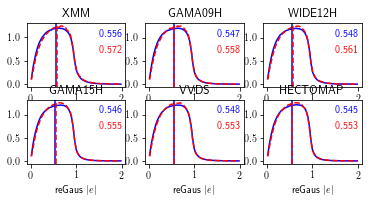

In [8]:
Dir='./wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_no_m/'

obsDis_snr  =   np.zeros(nbin2-1)
obsDis_res  =   np.zeros(nbin2-1)
obsDis_mag  =   np.zeros(nbin2-1)
obsDis_abs  =   np.zeros(nbin2-1)
obsNum      =   np.zeros(nbin2-1)

simRDis_snr =   np.zeros(nbin2-1)
simRDis_res =   np.zeros(nbin2-1)
simRDis_mag =   np.zeros(nbin2-1)
simRDis_abs =   np.zeros(nbin2-1)
simRNum     =   np.zeros(nbin2-1)

figN=   plt.figure()
figP=   plt.figure()
figM=   plt.figure()
figA=   plt.figure()

inFname=os.path.join(anaDir,'allSim.h5')
allSim=pd.read_hdf(inFname,key='data',mode='r')

for ii,fieldname in enumerate(utilities.field_names):
    # observation
    inFname =   os.path.join(Dir,'%s_no_m.fits' %(fieldname))
    data    =   pyfits.getdata(inFname)
    absE    =   utilities.get_abs_ellip(data)
    Res     =   utilities.get_res(data)
    mag     =   utilities.get_imag(data)
    snr     =   utilities.get_snr(data)
    ndata   =   len(data)*np.ones(nbin2-1)
    histRes =   np.histogram(Res,bins=resolution_bin,density=True)[0]
    histSnr =   np.histogram(snr,bins=snr_bin,density=True)[0]
    histMag =   np.histogram(mag,bins=mag_bin,density=True)[0]
    histAbsE=   np.histogram(absE,bins=absE_bin,density=True)[0]
    obscols =   [resGrid,histRes,snrGrid,histSnr,magGrid,histMag,absEGrid,histAbsE,ndata]
    t_dis_obs=   Table(data=obscols,names=datanames)
    
    # simulations
    anaFieldDir =   os.path.join(anaDir,'%s' %(fieldname))
    simOFname   =   os.path.join(anaFieldDir,'galDisSim.csv')
    data    =   allSim.xs(fieldname,level='fieldname').to_records()
    mask    =   utilities.get_wl_flags(data)
    data    =   data[mask]
    absE    =   utilities.get_abs_ellip(data)
    Res     =   utilities.get_res(data)
    mag     =   utilities.get_imag(data)
    snr     =   utilities.get_snr(data)
    weight  =   data['weight']
    ndata   =   np.sum(weight)*np.ones(nbin2-1)
    histRes =   np.histogram(Res,bins=resolution_bin,density=True,weights=weight)[0]
    histSnr =   np.histogram(snr,bins=snr_bin,density=True,weights=weight)[0]
    histMag =   np.histogram(mag,bins=mag_bin,density=True,weights=weight)[0]
    histAbsE=   np.histogram(absE,bins=absE_bin,density=True,weights=weight)[0]
    obscols =   [resGrid,histRes,snrGrid,histSnr,magGrid,histMag,absEGrid,histAbsE,ndata]
    t_dis_sim=   Table(data=obscols,names=datanames)
    t_dis_sim.write(simOFname)
    
    obsDis_snr  +=  t_dis_obs['histSnr']*t_dis_obs['num']
    obsDis_res  +=  t_dis_obs['histRes']*t_dis_obs['num']
    obsDis_mag  +=  t_dis_obs['histMag']*t_dis_obs['num']
    obsDis_abs  +=  t_dis_obs['histAbsE']*t_dis_obs['num']
    obsNum      +=  t_dis_obs['num']

    simRDis_snr +=  t_dis_sim['histSnr']*t_dis_sim['num']
    simRDis_res +=  t_dis_sim['histRes']*t_dis_sim['num']
    simRDis_mag +=  t_dis_sim['histMag']*t_dis_sim['num']
    simRDis_abs +=  t_dis_sim['histAbsE']*t_dis_sim['num']
    simRNum     +=  t_dis_sim['num']

    ax      =   figN.add_subplot(3,3,ii+1)
    gg1     =   t_dis_obs['gridSnr']
    hh1     =   t_dis_obs['histSnr']
    gg2     =   t_dis_sim['gridSnr']
    hh2     =   t_dis_sim['histSnr']
    dg      =   gg1[1]-gg1[0]
    ax.plot(gg1,hh1,'-',label='obs',c='b')
    ax.plot(gg2,hh2,'--',label='sim',c='r')
    ave1=np.sum(gg1*hh1)*dg
    ave2=np.sum(gg2*hh2)*dg
    ax.axvline(x=ave1,ls='-',c='blue')
    ax.axvline(x=ave2,ls='--',c='red')
    ymin,ymax=ax.get_ylim()
    ax.text(60.,0.78*ymax, '%.2f' %ave1,color='blue')
    ax.text(60.,0.52*ymax, '%.2f' %ave2,color='red')
    ax.set_xlabel('CModel SNR')
    ax.set_title(fieldname)

    ax      =   figP.add_subplot(3,3,ii+1)
    ax.set_xlabel('reGaus resolution')
    gg1     =   t_dis_obs['gridRes']
    hh1     =   t_dis_obs['histRes']
    gg2     =   t_dis_sim['gridRes']
    hh2     =   t_dis_sim['histRes']
    dg      =   gg1[1]-gg1[0]
    ax.plot(gg1,hh1,'-',label='obs',c='b')
    ax.plot(gg2,hh2,'--',label='sim',c='r')
    ave1=sum(gg1*hh1)*dg
    ave2=sum(gg2*hh2)*dg
    ax.axvline(x=ave1,ls='-',c='blue')
    ax.axvline(x=ave2,ls='--',c='red')
    ymin,ymax=ax.get_ylim()
    ax.text(0.08,0.78*ymax, '%.3f' %ave1,color='blue')
    ax.text(0.08,0.52*ymax, '%.3f' %ave2,color='red')
    ax.set_title(fieldname)

    ax      =   figM.add_subplot(3,3,ii+1)
    ax.set_xlabel('CModel mag')
    gg1     =   t_dis_obs['gridMag']
    hh1     =   t_dis_obs['histMag']
    gg2     =   t_dis_sim['gridMag']
    hh2     =   t_dis_sim['histMag']
    dg      =   gg1[1]-gg1[0]
    ax.plot(gg1,hh1,'-',label='obs',c='b')
    ax.plot(gg2,hh2,'--',label='sim',c='r')
    ave1=sum(gg1*hh1)*dg
    ave2=sum(gg2*hh2)*dg
    ax.axvline(x=ave1,ls='-',c='blue')
    ax.axvline(x=ave2,ls='--',c='red')
    ymin,ymax=ax.get_ylim()
    ax.text(22.,0.78*ymax, '%.2f' %ave1,color='blue')
    ax.text(22.,0.52*ymax, '%.2f' %ave2,color='red')
    ax.set_title(fieldname)

    ax      =   figA.add_subplot(3,3,ii+1)
    ax.set_xlabel(r'reGaus $|e|$')
    gg1     =   t_dis_obs['gridAbsE']
    hh1     =   t_dis_obs['histAbsE']
    gg2     =   t_dis_sim['gridAbsE']
    hh2     =   t_dis_sim['histAbsE']
    dg      =   gg1[1]-gg1[0]
    ax.plot(gg1,hh1,'-',label='obs',c='b')
    ax.plot(gg2,hh2,'--',label='sim',c='r')
    ave1=sum(gg1*hh1)*dg
    ave2=sum(gg2*hh2)*dg
    ax.axvline(x=ave1,ls='-',c='blue')
    ax.axvline(x=ave2,ls='--',c='red')
    ymin,ymax=ax.get_ylim()
    ax.text(1.5,0.78*ymax, '%.3f' %ave1,color='blue')
    ax.text(1.5,0.52*ymax, '%.3f' %ave2,color='red')
    ax.set_title(fieldname)

obsDis_snr /=   obsNum
obsDis_res /=   obsNum
obsDis_mag /=   obsNum
obsDis_abs /=   obsNum

simRDis_snr /=  simRNum
simRDis_res /=  simRNum
simRDis_mag /=  simRNum
simRDis_abs /=  simRNum

In [9]:
ax      =   figN.add_subplot(3,3,7)
gg      =   snrGrid
hh1     =   obsDis_snr
hh2     =   simRDis_snr
dg      =   gg[1]-gg[0]
ax.plot(gg,hh1,'-',label='obs',c='b')
ax.plot(gg,hh2,'--',label='sim',c='r')
ave1=sum(gg*hh1)*dg
ave2=sum(gg*hh2)*dg
ax.axvline(x=ave1,ls='-',c='blue')
ax.axvline(x=ave2,ls='--',c='red')
ymin,ymax=ax.get_ylim()
ax.text(60.,0.78*ymax, '%.2f' %ave1,color='blue')
ax.text(60.,0.52*ymax, '%.2f' %ave2,color='red')
ax.set_xlabel('CModel SNR')
ax.set_title('All')
ax      =   figN.add_subplot(3,3,8)
data_line = mlines.Line2D([], [], color='blue', ls='-', label='Observation')
sims_line = mlines.Line2D([], [], color='red', ls='-',label='Simulation')
ax.legend(handles=[data_line,sims_line],fontsize=15)
ax.set_axis_off()
figN.tight_layout()

ax      =   figP.add_subplot(3,3,7)
gg      =   resGrid
hh1     =   obsDis_res
hh2     =   simRDis_res
dg      =   gg[1]-gg[0]
ax.plot(gg,hh1,'-',label='obs',c='b')
ax.plot(gg,hh2,'--',label='sim',c='r')
ave1=sum(gg*hh1)*dg
ave2=sum(gg*hh2)*dg
ax.axvline(x=ave1,ls='-',c='blue')
ax.axvline(x=ave2,ls='--',c='red')
ymin,ymax=ax.get_ylim()
ax.text(0.08,0.78*ymax, '%.3f' %ave1,color='blue')
ax.text(0.08,0.52*ymax, '%.3f' %ave2,color='red')
ax.set_xlabel('reGaus resolution')
ax.set_title('All')
ax      =   figP.add_subplot(3,3,8)
data_line = mlines.Line2D([], [], color='blue', ls='-', label='Observation')
sims_line = mlines.Line2D([], [], color='red', ls='-',label='Simulation')
ax.legend(handles=[data_line,sims_line],fontsize=15)
ax.set_axis_off()
figP.tight_layout()

ax      =   figM.add_subplot(3,3,7)
gg      =   magGrid
hh1     =   obsDis_mag
hh2     =   simRDis_mag
dg      =   gg[1]-gg[0]
ax.plot(gg,hh1,'-',label='obs',c='b')
ax.plot(gg,hh2,'--',label='sim',c='r')
ave1=sum(gg*hh1)*dg
ave2=sum(gg*hh2)*dg
ax.axvline(x=ave1,ls='-',c='blue')
ax.axvline(x=ave2,ls='--',c='red')
ymin,ymax=ax.get_ylim()
ax.text(22.,0.78*ymax, '%.2f' %ave1,color='blue')
ax.text(22.,0.52*ymax, '%.2f' %ave2,color='red')
ax.set_xlabel('CModel mag')
ax.set_title('All')
ax      =   figM.add_subplot(3,3,8)
data_line = mlines.Line2D([], [], color='blue', ls='-', label='Observation')
sims_line = mlines.Line2D([], [], color='red', ls='-',label='Simulation')
ax.legend(handles=[data_line,sims_line],fontsize=15)
ax.set_axis_off()
figM.tight_layout()

ax      =   figA.add_subplot(3,3,7)
gg      =   absEGrid
hh1     =   obsDis_abs
hh2     =   simRDis_abs
dg      =   gg[1]-gg[0]
ax.plot(gg,hh1,'-',label='obs',c='b')
ax.plot(gg,hh2,'--',label='sim',c='r')
ave1=sum(gg*hh1)*dg
ave2=sum(gg*hh2)*dg
ax.axvline(x=ave1,ls='-',c='blue')
ax.axvline(x=ave2,ls='--',c='red')
ymin,ymax=ax.get_ylim()
ax.text(1.5,0.78*ymax, '%.3f' %ave1,color='blue')
ax.text(1.5,0.52*ymax, '%.3f' %ave2,color='red')
ax.set_xlabel(r'reGaus $\mid e \mid$')
ax.set_title('All')
ax      =   figA.add_subplot(3,3,8)
data_line = mlines.Line2D([], [], color='blue', ls='-', label='Observation')
sims_line = mlines.Line2D([], [], color='red', ls='-',label='Simulation')
ax.legend(handles=[data_line,sims_line],fontsize=15)
ax.set_axis_off()
figA.tight_layout()

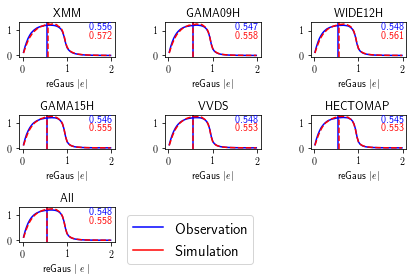

In [10]:
figA

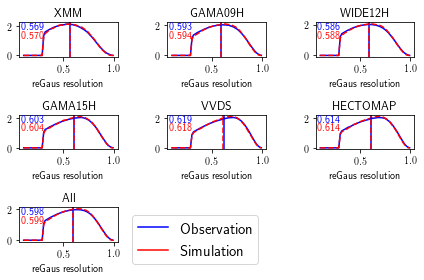

In [11]:
figP

In [12]:
pltDir  =   os.path.join(anaDir,'plot/galDis1D/')
if not os.path.isdir(pltDir):
    os.mkdir(pltDir)

figN.savefig(os.path.join(pltDir,'snrDis_reCheck.eps'))
figP.savefig(os.path.join(pltDir,'resolutionDis_reCheck.eps'))
figM.savefig(os.path.join(pltDir,'magDis_reCheck.eps'))
figA.savefig(os.path.join(pltDir,'absEDis_reCheck.eps'))

figN.savefig(os.path.join(pltDir,'snrDis_reCheck.png'))
figP.savefig(os.path.join(pltDir,'resolutionDis_reCheck.png'))
figM.savefig(os.path.join(pltDir,'magDis_reCheck.png'))
figA.savefig(os.path.join(pltDir,'absEDis_reCheck.png'))